# 03 · Is the fouling locked to the moon?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/EngMtaleb/chemai/blob/main/projects/p04_tide_fouling/notebooks/03_the_tide_test.ipynb)

If the fouling load at an intake rose and fell with the tide, part of the plant's future fouling
would be known **years** ahead — the tide tables are astronomy. That would be worth a lot. This
notebook runs the test exactly as it was declared before it ran
(`DECLARED_BEFORE_RUN.md`, commit `1989858`):

> - **Tide block**: cos/sin at M2 (12.4206 h), N2 (12.6583 h), O1 (25.8193 h), M4 (6.2103 h).
> - **Null**: 999 surrogates. Episodes closer than 72 h form one shift block. In each surrogate
>   every block's clock is moved by k whole weeks, k drawn independently from ±1…52.
>   Whole weeks keep time of day and day of week; only the moon is scrambled. The data are never moved.
> - **H1** passes at p ≤ 0.01. **Calibration**: placebo periods (11.0, 13.5, 27.0, 5.3 h) must give
>   p > 0.01. **Confirmation**: fitted before 2014, frozen, must explain the runs after it.

**Data:** a public seawater ultrafiltration (UF) pilot record, pre-treatment for a reverse-osmosis pilot, 2012–2015: Zenodo [4630769](https://zenodo.org/records/4630769), also Dryad [doi:10.5068/D1310B](https://doi.org/10.5068/D1310B), CC0. The site is not named here. The notebooks read the tables committed in `results/`; the 356 MB raw archive is needed only where a cell says so.

Script version: `step3_power.py`, `step4_tide_test.py` · record: `VALIDATION.md`, sections 3–6.

In [1]:
# Setup. In Google Colab this clones the repository and installs the package (about a minute).
# On your own machine, run from a clone after:  pip install -e ".[viz,data]"
import os, subprocess, sys
from pathlib import Path
REF = "main"        # before the Project 4 pull request is merged, use "p04-tide-fouling"
if "google.colab" in sys.modules:
    if not Path("/content/chemai").exists():
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--branch", REF,
                        "https://github.com/EngMtaleb/chemai.git", "/content/chemai"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", "/content/chemai[viz,data]"], check=True)
    sys.path.insert(0, "/content/chemai")
    ROOT = Path("/content/chemai")
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
P4 = ROOT / "projects" / "p04_tide_fouling"
RES = P4 / "results"

import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)
INK, MUTED, BLUE, ORANGE, GREEN, RED, SUN = "#1f2933", "#7b8794", "#2f6fb2", "#d9822b", "#3f8f5a", "#c23b3b", "#f2c14e"

def load(name):
    """A committed result file from projects/p04_tide_fouling/results/."""
    return json.loads((RES / name).read_text())

In [2]:
from chemai.evaluation.tide_test import (CONSTITUENTS, PLACEBO, TideTestConfig, _fit, block_shifts,
                                         confirm_out_of_sample, prepare, rotation_stack, tide_design, tide_test)
seg = pd.read_parquet(RES / "segments.parquet")
cfg = TideTestConfig()
prep = prepare(seg, "fouling_pct_h", cfg)          # the declared base model, residualised
print(f"{len(prep.y):,} segments, {len(np.unique(prep.run))} runs, {len(np.unique(prep.episode))} episodes, "
      f"{len(np.unique(prep.block))} shift blocks; base model {prep.n_base} columns")

14,998 segments, 106 runs, 86 episodes, 38 shift blocks; base model 284 columns


## 1. Why whole weeks

Many things in a plant swing about every 12 hours: shifts, sunlight, a controller, the temperature.
Only the tide keeps the **same phase against the astronomical clock** across runs months apart. Moving a
block's clock by whole weeks keeps everything daily and weekly where it was, and moves the moon:

In [3]:
rows = []
for k in (1, 2, 3, 4, 13, 52):
    h = k * 7 * 24
    rows.append({"shift": f"{k} week{'s' if k > 1 else ''}", "time of day moves (h)": h % 24,
                 "weekday moves (days)": (h // 24) % 7,
                 "M2 phase moves (°)": round(360 * (h / CONSTITUENTS["M2"] % 1)),
                 "O1 phase moves (°)": round(360 * (h / CONSTITUENTS["O1"] % 1))})
pd.DataFrame(rows)

,shift,time of day moves (h),weekday moves (days),M2 phase moves (°),O1 phase moves (°)
0,1 week,0,0,189,182
1,2 weeks,0,0,19,5
2,3 weeks,0,0,208,187
3,4 weeks,0,0,37,10
4,13 weeks,0,0,301,212
5,52 weeks,0,0,125,126


So the 999 surrogates are 999 versions of the record in which the day, the week, the seasons, the
operators and the noise are all exactly as they were — and the moon is somewhere else. If the real
moon explains more than almost all of them, the fouling follows the moon.

## 2. Can the test find a tide? (a planted one)

Before the real test, the declaration fixed how big a tide the record could see
(`step3_power.py`: a wave added to noise shaped like the data, 200 trials per size). Here is the
same idea once, done the blunt way: add a wave to the **real** fouling rates and test.

In [4]:
rng = np.random.default_rng(4)
med = float(np.median(prep.y))
amp = 0.10 * med / 1.975                       # a wave whose 5-95 % swing is 10 % of the median rate
phase = rng.uniform(0, 360)
t_h = (seg.t_std - pd.Timestamp("2000-01-01")) / pd.Timedelta(hours=1)
planted = seg.assign(planted=seg.fouling_pct_h + amp * np.cos(2 * np.pi * t_h / CONSTITUENTS["M2"] - np.radians(phase)))
r = tide_test(prepare(planted, "planted", cfg), CONSTITUENTS, cfg, "planted")
print(f"planted: M2, amplitude {amp:.2f} %/h, phase {phase:.0f}°")
print(f"found:   p = {r.p_value:.3f}; M2 amplitude {r.amplitudes['M2']:.2f} %/h, phase {r.phases_deg['M2']:.0f}°")
pw = load("step3_power.json")["fouling_pct_h"]["detection_rate_at_p_le_0.01"]
pd.Series({f"{float(k):.0%} of the median": v for k, v in pw.items()}, name="found at p ≤ 0.01 (200 trials)").to_frame()

planted: M2, amplitude 0.67 %/h, phase 340°
found:   p = 0.001; M2 amplitude 0.86 %/h, phase 336°


,found at p ≤ 0.01 (200 trials)
2% of the median,0.030
5% of the median,0.430
10% of the median,0.995
20% of the median,1.000


Found, at the right phase. (The amplitude comes back a little larger because the record's own small
M2 term — 0.21 %/h, in the next section — happens to sit near the same phase.) In the power study,
a wave whose swing is 10 % of the median rate — about 1.3 %/h — is found 99.5 % of the time;
5 % is a coin toss (43 %); 2 % is invisible. That was fixed before the real alignment was ever
looked at.

## 3. The test

In [5]:
res = tide_test(prep, CONSTITUENTS, cfg, "fouling_pct_h")
print(f"partial R² {res.partial_r2:.5f} (95 % of the null below {res.null_partial_r2_q95:.5f})  ->  p = {res.p_value:.3f}")
pd.DataFrame({"amplitude, %/h": res.amplitudes, "phase, °": res.phases_deg}).round(3)

partial R² 0.00101 (95 % of the null below 0.00138)  ->  p = 0.244


,"amplitude, %/h","phase, °"
M2,0.206,325.612
N2,0.246,9.451
O1,0.125,70.334
M4,0.092,210.305


p from this loop: 0.244


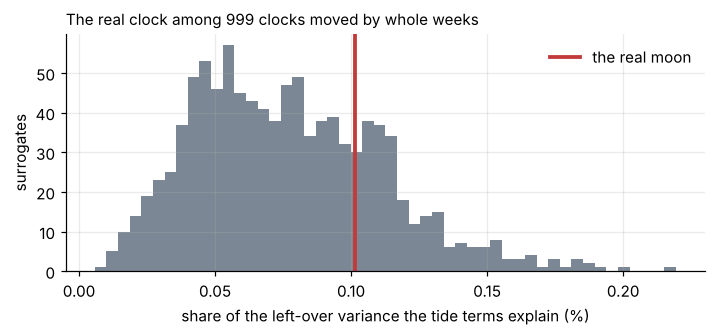

In [6]:
# the null distribution behind that p (the same 999 surrogates the function draws)
design = tide_design(prep, CONSTITUENTS)
zy, k = design.zcat.T @ prep.y_res, len(design.blocks)
ss_obs = _fit(design, zy, rotation_stack(design, np.zeros(k)))[0]
rng = np.random.default_rng(cfg.seed)
null = np.array([_fit(design, zy, rotation_stack(design, block_shifts(k, rng, cfg.shift_weeks)))[0]
                 for _ in range(cfg.n_surrogates)])
ss_tot = prep.y_res @ prep.y_res
print("p from this loop:", (1 + np.sum(null >= ss_obs)) / (1 + len(null)))
fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.hist(null / ss_tot * 100, bins=50, color=MUTED)
ax.axvline(ss_obs / ss_tot * 100, color=RED, lw=2.5, label="the real moon")
ax.set_xlabel("share of the left-over variance the tide terms explain (%)"); ax.set_ylabel("surrogates")
ax.legend(frameon=False); ax.set_title("The real clock among 999 clocks moved by whole weeks", loc="left", fontsize=10)
plt.show()

**p = 0.244.** The real moon explains 0.10 % of the left-over variation; a quarter of the moved
clocks explain more. H1 fails. Under the declaration that means: **no tide effect at this intake
larger than about 10 % of the median fouling rate.**

## 4. The checks around it

In [7]:
placebo = tide_test(prep, PLACEBO, cfg, "fouling_pct_h", with_ranges=False)
split = pd.Timestamp("2014-01-01")
conf = confirm_out_of_sample(prepare(seg[seg.t_std < split], "fouling_pct_h", cfg),
                             prepare(seg[seg.t_std >= split], "fouling_pct_h", cfg), CONSTITUENTS, cfg)
c1 = tide_test(prepare(seg, "pump_speed", cfg), CONSTITUENTS, cfg, "pump_speed", with_ranges=False)
c2 = tide_test(prepare(seg, "p_mf_in", cfg), CONSTITUENTS, cfg, "p_mf_in", with_ranges=False)
pd.DataFrame([
    ("placebo periods 11, 13.5, 27, 5.3 h (calibration)", f"p = {placebo.p_value:.3f}", "passes: the test does not invent signals"),
    ("fitted before 2014, frozen, scored after (confirmation)", f"explains {conf['oos_variance_share']:+.2%}, p = {conf['p_value']:.3f}", "fails: nothing carries over"),
    ("feed-pump speed (control C1)", f"p = {c1.p_value:.3f}", "fails"),
    ("pump discharge pressure (control C2)", f"p = {c2.p_value:.3f}", "fails at 0.01"),
], columns=["check", "result", "reading"])

,check,result,reading
0,"placebo periods 11, 13.5, 27, 5.3 h (calibration)",p = 0.330,passes: the test does not invent signals
1,"fitted before 2014, frozen, scored after (conf...","explains -1.34%, p = 0.248",fails: nothing carries over
2,feed-pump speed (control C1),p = 0.349,fails
3,pump discharge pressure (control C2),p = 0.015,fails at 0.01


The calibration holds — on made-up periods the test stays quiet, so a negative is a negative. The
positive controls were meant to show that the intake's hydraulics feel the tide; at the declared
0.01 they do not. The declaration said what that would mean: *"the feed may pass through storage
that hides the tide."*

## 5. Exploratory, and labelled so: does the pump feel the moon at all?

Not in the declaration: fit an M2 wave in each long episode separately and look at the phases. A
tide would make them point the same way every time; noise points anywhere.

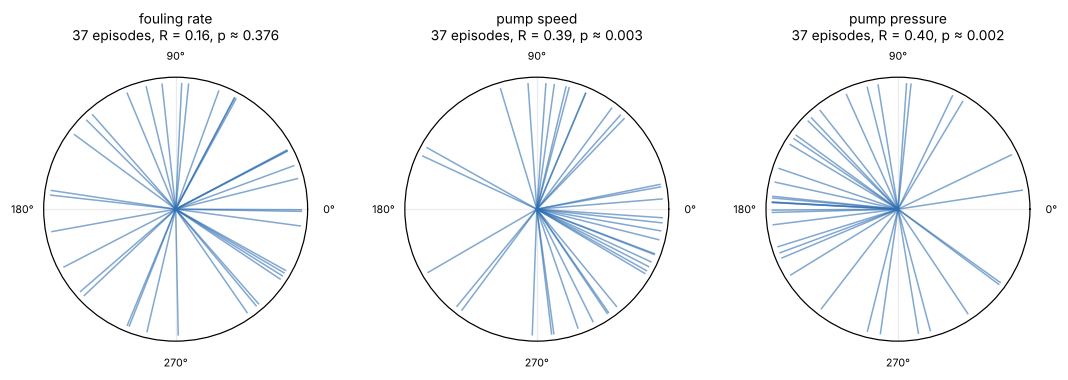

In [8]:
def episode_phases(col):
    p = prepare(seg, col, cfg)
    w = 2 * np.pi * p.t_hours / CONSTITUENTS["M2"]
    ph = []
    for e in np.unique(p.episode):
        sel = p.episode == e
        if np.ptp(p.t_hours[sel]) < 48:
            continue
        c = np.linalg.lstsq(np.column_stack([np.cos(w[sel]), np.sin(w[sel])]), p.y_res[sel], rcond=None)[0]
        ph.append(np.arctan2(c[1], c[0]))
    ph = np.array(ph)
    n, rbar = len(ph), abs(np.mean(np.exp(1j * ph)))
    z = n * rbar ** 2
    p_rayleigh = np.exp(np.sqrt(1 + 4 * n + 4 * (n ** 2 - (n * rbar) ** 2)) - (1 + 2 * n))
    return ph, n, rbar, min(1.0, p_rayleigh)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.3), subplot_kw={"projection": "polar"})
for ax, (title, col) in zip(axes, [("fouling rate", "fouling_pct_h"), ("pump speed", "pump_speed"),
                                   ("pump pressure", "p_mf_in")]):
    ph, n, rbar, pr = episode_phases(col)
    for a in ph:
        ax.plot([a, a], [0, 1], color=BLUE, lw=1, alpha=0.6)
    ax.set_yticks([]); ax.set_xticks(np.radians([0, 90, 180, 270]), ["0°", "90°", "180°", "270°"], fontsize=7)
    ax.set_title(f"{title}\n{n} episodes, R = {rbar:.2f}, p ≈ {pr:.3f}", fontsize=9)
plt.tight_layout(); plt.show()

The fouling rate's episode phases point anywhere. The pump's do not: speed and pressure line up on
the moon, in opposite phases — the pump works harder at one tide and less at the other. So the feed
**did** feel the tide, faintly; the fouling did not follow it. (Exploratory: found after the
declared controls failed, so it is a lead, not a result.)

## What this says, and what it does not

- **No tide-locked fouling at this intake bigger than about 10 % of the median rate** (power 99.5 %),
  over 2012–2015, with a calibrated test.
- A smaller effect (5 % of the rate) could hide: the record finds that size only half the time.
- One pilot, one intake, fed through storage that seems to damp the tide. An intake drawing straight
  from the sea could behave differently — and this test, now in the package as `series_test` and in
  the service at `/sun/test`, is how to find out on any plant log with a clock.

For a plant that wants to run on the sun, a negative here is good news: there is one thing less to
schedule around. The next notebook asks the question that matters for solar operation.